# 02 — KV cache lab

A transformer's attention keeps, for every past token and every layer, a **key** and a
**value** vector. Re-using them (instead of recomputing) is the *KV cache*.

R2's prompt is ~965 tokens of instructions + few-shot examples followed by a ~20-token
user request. The instructions never change, so R2 computes their KV once
(**prefix cache**), optionally saves it to disk (**persistent cache**), and per
request only *prefills* the new suffix.

| mode | per request prefill | after restart |
|---|---|---|
| `none` | whole prompt (~840 tok) | — |
| `prefix` | suffix only (~20 tok) | rebuild prefix (~1 s) |
| `persistent` | suffix only | load from disk (ms) |

**Size of the cache** for one token:
$\text{bytes/token} = 2 \times L \times H_{kv} \times d_{head} \times \text{bytes}$

In [1]:
# --- setup: make the repo importable and quiet logs ---
import os, sys, logging
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_OFFLINE", "1")  # models are already cached → fully local
logging.basicConfig(level=logging.WARNING)
print("repo:", ROOT)

repo: /Users/siavash/Projects/articles/narrow-ai-with-kv


In [2]:
import json
from narrow_ai.models.hub import local_or_repo
from narrow_ai.settings import load_settings
s = load_settings()
cfg = json.load(open(Path(local_or_repo(s.model.model_id)) / "config.json"))
L, H, D = cfg["num_hidden_layers"], cfg["num_key_value_heads"], cfg["head_dim"]
per_tok = 2 * L * H * D * 2   # K and V, bf16/fp16 = 2 bytes
print(f"layers={L} kv_heads={H} head_dim={D}  →  {per_tok/1024:.0f} KiB per token")
print(f"GQA saves {cfg['num_attention_heads']/H:.0f}x vs. full multi-head KV")

layers=28 kv_heads=8 head_dim=128  →  112 KiB per token
GQA saves 2x vs. full multi-head KV


In [3]:
from narrow_ai.models.model_registry import create_backend
from narrow_ai.assistant.orchestrator import IntentEngine
from narrow_ai.intents.registry import default_registry
from narrow_ai.models.prompt_templates import INTENT_PREFILL

s.model.backend = "mlx"
backend = create_backend(s)
engine = IntentEngine(s, backend, default_registry())
backend.set_cache_mode("prefix"); backend.warmup(engine.system_prompt)
st = backend.cache_stats()
theory = st.prefix_tokens * per_tok
alloc = ((st.prefix_tokens + 255) // 256) * 256 * per_tok   # mlx grows the cache in 256-token steps
print(f"prefix tokens       : {st.prefix_tokens}")
print(f"theory (exact)      : {theory/1e6:.1f} MB")
print(f"theory (256-step)   : {alloc/1e6:.1f} MB")
print(f"measured cache bytes: {backend.kv.nbytes()/1e6:.1f} MB")

prefix tokens       : 1118
theory (exact)      : 128.2 MB
theory (256-step)   : 146.8 MB
measured cache bytes: 146.8 MB


## Experiment 1 — cache modes on held-out requests

In [4]:
from narrow_ai.evaluation.dataset import load_eval_cases
from narrow_ai.evaluation.kv_bench import run_kv_benchmark
import pandas as pd

utts = [c.utterance for c in load_eval_cases(ROOT / "data/eval_heldout.jsonl")][:15]
report = run_kv_benchmark(backend, s, utts)
df = pd.DataFrame(report["modes"]).T
df[["setup_source", "setup_ms", "ttft_ms_mean", "total_ms_mean", "prefilled_tokens_mean",
    "ttft_speedup_vs_none", "output_match_vs_none"]]

,setup_source,setup_ms,ttft_ms_mean,total_ms_mean,prefilled_tokens_mean,ttft_speedup_vs_none,output_match_vs_none
none,none,1498.2,1438.1,1595.4,1140.3,NaN,1.0
prefix,built,1488.2,72.4,216.2,22.3,19.87,1.0
persistent,disk,81.7,69.6,212.0,22.3,20.67,1.0


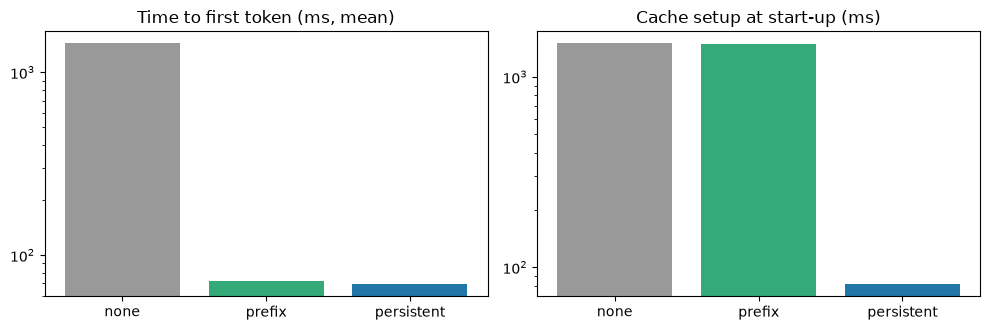

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
modes = list(report["modes"])
ax[0].bar(modes, [report["modes"][m]["ttft_ms_mean"] for m in modes], color=["#999", "#3a7", "#27a"])
ax[0].set_title("Time to first token (ms, mean)"); ax[0].set_yscale("log")
ax[1].bar(modes, [max(report["modes"][m]["setup_ms"], 0.1) for m in modes], color=["#999", "#3a7", "#27a"])
ax[1].set_title("Cache setup at start-up (ms)"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

**Equivalence.** With greedy decoding the cached path *should* produce the same text.
Splitting the prefill into two matmuls changes floating-point rounding, so a rare
mismatch is possible — inspect them here:

In [6]:
raw = report["raw"]
for i, (a, b) in enumerate(zip(raw["none"]["outputs"], raw["prefix"]["outputs"])):
    if a != b:
        print(utts[i % len(utts)]); print("  none  :", a); print("  prefix:", b)
print("match rate:", report["modes"]["prefix"]["output_match_vs_none"])

match rate: 1.0


## Experiment 2 — how does the benefit scale with prompt length?

We pad the system prompt with extra (static) documentation and measure TTFT
with and without the prefix cache. Use the slider/button to re-run.

In [7]:
import statistics
import ipywidgets as W
from IPython.display import display

FILLER = ("Reference: R2 only operates inside the active workspace; paths are relative; "
          "secrets such as .env files are never read; destructive commands are refused. ")

def ttft_for(system, mode, queries, reps=1):
    backend.set_cache_mode(mode)
    backend.warmup(system)
    out = []
    for _ in range(reps):
        for q in queries:
            msgs = [{"role": "system", "content": system}, {"role": "user", "content": q}]
            g = backend.generate(msgs, prefill=INTENT_PREFILL, constrain_intents=engine.allowed, max_tokens=24)
            out.append(g.ttft_ms)
    return statistics.mean(out)

def scaling(pads=(0, 20, 60, 140), queries=("git status", "find json files", "open xcode")):
    rows = []
    for p in pads:
        system = engine.system_prompt + "\n" + FILLER * p
        n = len(backend.encode(system))
        rows.append({"system_tokens": n,
                     "none_ms": ttft_for(system, "none", queries),
                     "prefix_ms": ttft_for(system, "prefix", queries)})
    return pd.DataFrame(rows)

scale_df = scaling()
scale_df

,system_tokens,none_ms,prefix_ms
0,1113,1434.758792,68.914555
1,1714,2355.540986,74.385736
2,2914,4871.309555,82.349597
3,5314,14854.519264,126.694958


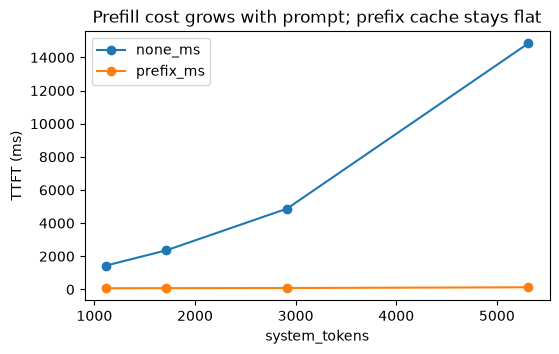

In [8]:
ax = scale_df.plot(x="system_tokens", y=["none_ms", "prefix_ms"], marker="o", figsize=(6, 3.5))
ax.set_ylabel("TTFT (ms)"); ax.set_title("Prefill cost grows with prompt; prefix cache stays flat")
plt.show()

In [9]:
pad = W.IntSlider(value=200, min=0, max=400, step=50, description="filler ×")
btn = W.Button(description="Measure", button_style="primary")
res = W.Output()
def go(_):
    with res:
        res.clear_output()
        system = engine.system_prompt + "\n" + FILLER * pad.value
        n = len(backend.encode(system))
        a = ttft_for(system, "none", ["git status"]); b = ttft_for(system, "prefix", ["git status"])
        print(f"{n} system tokens → no cache {a:.0f} ms | prefix cache {b:.0f} ms | speed-up {a/b:.1f}x")
btn.on_click(go)
display(W.HBox([pad, btn]), res)

Output()

## Take-aways

* For a narrow assistant the **prompt is mostly static**, so prefix caching removes
  most of the latency; a long few-shot prompt becomes nearly free per request.
* The persistent cache turns a ~1 s prefix rebuild at start-up into a disk load.
* KV *compression* (quantised KV, eviction) matters when memory is the bottleneck —
  here the cache is ~0.1 GB, so it is left as future work.